# Fase 1 · Diseño del centro de datos e ingesta  (RA1 · UD1)

**Reto:** la autoridad portuaria quiere una plataforma que reúna los datos del puerto (escalas de buques,
posiciones AIS, sensores, contenedores) y responda preguntas de negocio. Vosotros diseñáis el almacenamiento,
ingestáis los datos, elegís formatos, los procesáis y presentáis los resultados al «cliente».

| Parte | Qué hacéis | CE |
|---|---|---|
| A | Explorar los datos crudos en HDFS | 1.a, 1.b |
| B | Leer con esquema explícito y controlar registros corruptos | 1.b |
| C | Comparar formatos de almacenamiento | 1.c |
| D | Zona *bronze* en Parquet particionado | 1.c, 1.d |
| E | Procesar con Spark SQL | 1.d |
| F | Presentar resultados al cliente | 1.e |

Las celdas marcadas con **✏️ TAREA** son vuestras. Todo lo demás funciona tal cual: ejecutadlo, leedlo y entendedlo
(os puedo pedir que expliquéis cualquier línea).

Zonas del lago de datos del proyecto:
```
/puerto/raw        tal como llegan (CSV, JSON...)             ← ingesta.sh
/puerto/bronze     mismos datos, tipados, en formato columnar  ← esta fase
/puerto/silver     datos validados y limpios                   ← fase 3
/puerto/gold       agregados listos para negocio               ← fases 1 y 5
/puerto/cuarentena filas que no superan la calidad             ← fase 3
/puerto/control    manifiestos, registros de ingesta e informes
```

In [1]:
from pyspark.sql import functions as F, types as T
from puerto.sesion import crear_spark, cronometro, sello
PAREJA = "04"   # ✏️ vuestro número de pareja: su salida debe verse en las capturas de la memoria
sello(PAREJA)
from puerto import hdfs_web as h
import pandas as pd, matplotlib.pyplot as plt, os
spark = crear_spark("F1-ingesta-formatos")
os.makedirs("/workspace/entregas/F1", exist_ok=True)

EVIDENCIA · Pareja 04 · 2026-11-18 19:02:09 · PC AMY · contenedor jupyter


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/18 19:02:14 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## A · Exploración de los datos crudos
La ingesta por lotes (`.\bda.ps1 ingesta`) ya ha copiado los ficheros a `/puerto/raw`. Revisad el script
`scripts/hdfs/ingesta.sh`: crea las zonas, copia con `put -f` (idempotente) y deja un registro en `/puerto/control`.

In [2]:
for carpeta in ["maestros", "escalas", "negocio", "contenedores", "sensores", "ais"]:
    r = h.resumen(f"/puerto/raw/{carpeta}")
    print(f"{carpeta:13} {r['ficheros']:4} ficheros  {r['tamano']:>10} lógicos  {r['en_disco']:>10} en disco")

maestros         3 ficheros     33.6 KB lógicos    100.7 KB en disco
escalas          2 ficheros      1.1 MB lógicos      3.3 MB en disco
negocio         10 ficheros      5.9 MB lógicos     17.7 MB en disco
contenedores     1 ficheros     40.7 MB lógicos    122.1 MB en disco
sensores        60 ficheros     67.6 MB lógicos    202.9 MB en disco
ais             60 ficheros    124.9 MB lógicos    374.6 MB en disco


**✏️ TAREA A1.** ¿Por qué el espacio «en disco» es aproximadamente el triple del lógico? ¿Qué propiedad de
`docker/hadoop.env` lo explica? Contestad en la memoria.

**✏️ TAREA A2.** La ingesta actual es **por lotes** (todo de golpe). Los datos AIS en realidad llegan de forma
continua. Describid en la memoria cómo haríais una ingesta **incremental** (idea: `scripts/hdfs/simular_llegada_ais.sh`)
y qué herramientas se usan en la industria (Kafka, NiFi, Flume, Spark Structured Streaming...).
Indicad para cada fuente del proyecto: frecuencia de llegada, volumen/día y mecanismo de ingesta propuesto.

## B · Lectura con esquema explícito
Inferir el esquema (`inferSchema=True`) obliga a leer los datos dos veces y puede equivocarse.
En producción **siempre** se declara el esquema. Además, pedimos a Spark que no descarte en silencio
las líneas rotas, sino que las guarde en una columna `_corrupto`.

In [3]:
esquema_ais = T.StructType([
    T.StructField("mmsi", T.StringType()),
    T.StructField("ts", T.StringType()),
    T.StructField("lat", T.DoubleType()),
    T.StructField("lon", T.DoubleType()),
    T.StructField("sog", T.DoubleType()),
    T.StructField("cog", T.DoubleType()),
    T.StructField("estado_nav", T.IntegerType()),
    T.StructField("estacion", T.StringType()),
    T.StructField("_corrupto", T.StringType()),
])
ais_raw = (spark.read.schema(esquema_ais)
           .option("mode", "PERMISSIVE")
           .option("columnNameOfCorruptRecord", "_corrupto")
           .json("/puerto/raw/ais/"))
ais_raw.cache()
print("Posiciones AIS:", ais_raw.count())
print("Líneas corruptas:", ais_raw.filter(F.col("_corrupto").isNotNull()).count())
ais_raw.filter(F.col("_corrupto").isNotNull()).select("_corrupto").show(3, truncate=80)

Posiciones AIS: 945371
Líneas corruptas: 735
+------------------------------------------------------------------------------+
|                                                                     _corrupto|
+------------------------------------------------------------------------------+
|{"mmsi":"249880338","ts":"2025-06-06T14:35:11Z","lat":37.15284,"lon":-6.92899,|
|                       {"mmsi":"249880338","ts":"2025-06-06T18:57:05Z","lat":3|
|                                                     {"mmsi":"224546912","ts":|
+------------------------------------------------------------------------------+
only showing top 3 rows



In [4]:
esquema_escalas = T.StructType([
    T.StructField(c, t) for c, t in [
        ("id_escala", T.StringType()), ("imo", T.StringType()), ("buque", T.StringType()),
        ("id_naviera", T.StringType()), ("id_muelle", T.StringType()), ("tipo_trafico", T.StringType()),
        ("operacion", T.StringType()), ("mercancia", T.StringType()), ("toneladas", T.DoubleType()),
        ("teu", T.IntegerType()), ("eta", T.StringType()), ("ata", T.StringType()), ("atd", T.StringType()),
        ("origen", T.StringType()), ("destino", T.StringType()), ("practicaje", T.StringType()),
        ("pasajeros", T.IntegerType())]
])
escalas_raw = spark.read.schema(esquema_escalas).option("header", True).csv("/puerto/raw/escalas/")
escalas_raw.printSchema()
escalas_raw.show(5, truncate=False)

root
 |-- id_escala: string (nullable = true)
 |-- imo: string (nullable = true)
 |-- buque: string (nullable = true)
 |-- id_naviera: string (nullable = true)
 |-- id_muelle: string (nullable = true)
 |-- tipo_trafico: string (nullable = true)
 |-- operacion: string (nullable = true)
 |-- mercancia: string (nullable = true)
 |-- toneladas: double (nullable = true)
 |-- teu: integer (nullable = true)
 |-- eta: string (nullable = true)
 |-- ata: string (nullable = true)
 |-- atd: string (nullable = true)
 |-- origen: string (nullable = true)
 |-- destino: string (nullable = true)
 |-- practicaje: string (nullable = true)
 |-- pasajeros: integer (nullable = true)

+---------------+-------+---------------+----------+---------+-----------------+---------+------------------+---------+---+-------------------+-------------------+-------------------+----------+----------------------+----------+---------+
|id_escala      |imo    |buque          |id_naviera|id_muelle|tipo_trafico     |operacion|

**✏️ TAREA B1.** Leed `/puerto/raw/negocio/facturas_2025.csv`. Fijaos: separador `;`, **coma decimal** y fechas
`dd/mm/aaaa` (típico de un ERP español). Leedlo con esquema de texto y convertid `cantidad`, `precio_unitario` e
`importe` a número (pista: `F.regexp_replace(col, ",", ".").cast("double")`). Mostrad 5 filas y el esquema.

In [5]:
# ✏️ TAREA B1 · facturas_2025.csv (separador ';', coma decimal, fechas dd/MM/yyyy)

# 0. Cabecera real del fichero: con esquema explícito Spark asigna las columnas por POSICIÓN,
#    así que el esquema tiene que seguir este mismo orden (coincide con DICCIONARIO_DATOS.md).
spark.read.text("/puerto/raw/negocio/facturas_2025.csv").show(3, truncate=False)

# 1. Esquema de texto: las 11 columnas como String; los tipos los convertimos nosotros
columnas_facturas = ["num_factura", "linea", "fecha", "id_cliente", "cod_servicio", "cantidad",
                     "precio_unitario", "descuento_pct", "importe", "divisa", "comercial"]
esquema_facturas = T.StructType([T.StructField(c, T.StringType()) for c in columnas_facturas])

# 2. Lectura con separador ';'
facturas_raw = (spark.read.schema(esquema_facturas)
                .option("header", True).option("sep", ";")
                .csv("/puerto/raw/negocio/facturas_2025.csv"))

# 3. Coma decimal -> punto -> double ; fecha dd/MM/yyyy -> date
def a_numero(c):
    return F.regexp_replace(F.col(c), ",", ".").cast("double")

facturas = (facturas_raw
    .withColumn("linea", F.col("linea").cast("int"))
    .withColumn("fecha", F.to_date("fecha", "dd/MM/yyyy"))
    .withColumn("cantidad", a_numero("cantidad"))
    .withColumn("precio_unitario", a_numero("precio_unitario"))
    .withColumn("descuento_pct", a_numero("descuento_pct"))
    .withColumn("importe", a_numero("importe")))

# 4. 5 filas y el esquema
facturas.show(5, truncate=False)
facturas.printSchema()

# 5. Control: líneas leídas y conversiones fallidas (venía texto y ha quedado null)
print("Líneas de factura:", facturas.count())
conversiones = {"fecha": F.to_date("fecha", "dd/MM/yyyy"), "cantidad": a_numero("cantidad"),
                "precio_unitario": a_numero("precio_unitario"), "descuento_pct": a_numero("descuento_pct"),
                "importe": a_numero("importe")}
facturas_raw.select([F.sum((F.col(c).isNotNull() & expr.isNull()).cast("int")).alias(f"fallo_{c}")
                     for c, expr in conversiones.items()]).show()


+---------------------------------------------------------------------------------------------------------------+
|value                                                                                                          |
+---------------------------------------------------------------------------------------------------------------+
|num_factura;linea;fecha;id_cliente;cod_servicio;cantidad;precio_unitario;descuento_pct;importe;divisa;comercial|
|F2025-000001;1;09/08/2025;CLI0385;S11;97,28;26,30;10;2302,62;EUR;C02-Javier                                    |
|F2025-000002;1;19/07/2025;CLI0105;S10;954,43;8,33;5;7552,88;EUR;C02-Javier                                     |
+---------------------------------------------------------------------------------------------------------------+
only showing top 3 rows

+------------+-----+----------+----------+------------+--------+---------------+-------------+-------+------+----------+
|num_factura |linea|fecha     |id_cliente|cod_servicio|c

## C · ¿Qué formato de almacenamiento elegimos?
Escribimos las mismas posiciones AIS en seis formatos y medimos: **tiempo de escritura**, **tamaño en HDFS** y
**tiempo de dos consultas típicas**. La celda tarda unos minutos.

In [6]:
ais = ais_raw.filter(F.col("_corrupto").isNull()).drop("_corrupto")
formatos = [
    ("csv",            "csv",     {"header": "true"}),
    ("json",           "json",    {}),
    ("avro",           "avro",    {}),
    ("orc",            "orc",     {}),
    ("parquet_snappy", "parquet", {"compression": "snappy"}),
    ("parquet_zstd",   "parquet", {"compression": "zstd"}),
]
resultados = []
for nombre, fmt, opciones in formatos:
    ruta = f"/puerto/bench/ais_{nombre}"
    t = {}
    with cronometro(f"escritura {nombre}", t):
        ais.write.mode("overwrite").format(fmt).options(**opciones).save(ruta)
    lector = spark.read.format(fmt).options(**opciones)
    if fmt in ("csv", "json"):
        lector = lector.schema(ais.schema)
    df = lector.load(ruta)
    with cronometro(f"consulta completa {nombre}", t):
        df.groupBy("mmsi").agg(F.avg("sog")).count()
    with cronometro(f"consulta 2 columnas {nombre}", t):
        df.select("lat", "lon").where("lat > 37.1").count()
    r = h.resumen(ruta)
    resultados.append({"formato": nombre, "MB": round(r["bytes"] / 2**20, 1),
                       "escritura_s": t[f"escritura {nombre}"],
                       "consulta_completa_s": t[f"consulta completa {nombre}"],
                       "consulta_2col_s": t[f"consulta 2 columnas {nombre}"]})
comparativa = pd.DataFrame(resultados).set_index("formato")
comparativa.to_csv("/workspace/entregas/F1/comparativa_formatos.csv")
comparativa

[escritura csv] 2.22 s


[consulta completa csv] 1.53 s


[consulta 2 columnas csv] 1.00 s


[escritura json] 1.41 s


[consulta completa json] 1.19 s


[consulta 2 columnas json] 1.03 s


... (2 outputs left out)

[escritura orc] 1.51 s


[consulta completa orc] 1.06 s
[consulta 2 columnas orc] 0.44 s


[escritura parquet_snappy] 1.91 s
[consulta completa parquet_snappy] 0.59 s
[consulta 2 columnas parquet_snappy] 0.47 s
[escritura parquet_zstd] 0.81 s
[consulta completa parquet_zstd] 0.36 s
[consulta 2 columnas parquet_zstd] 0.25 s


,MB,escritura_s,consulta_completa_s,consulta_2col_s
formato,,,,
csv,63.6,2.220,1.530,1.004
json,124.8,1.408,1.189,1.026
avro,21.6,1.380,0.879,0.412
orc,16.9,1.509,1.056,0.442
parquet_snappy,11.3,1.914,0.585,0.468
parquet_zstd,7.6,0.807,0.357,0.248


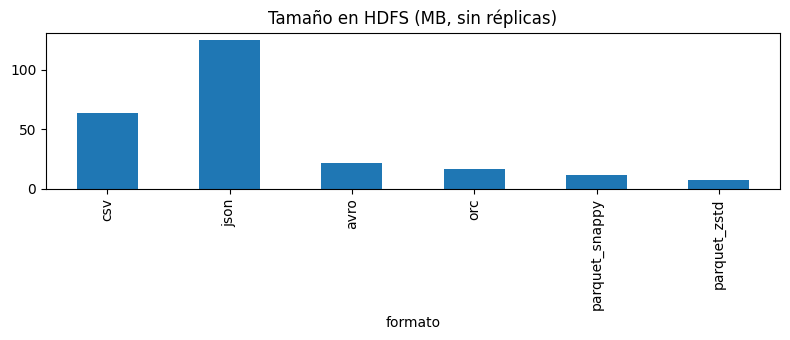

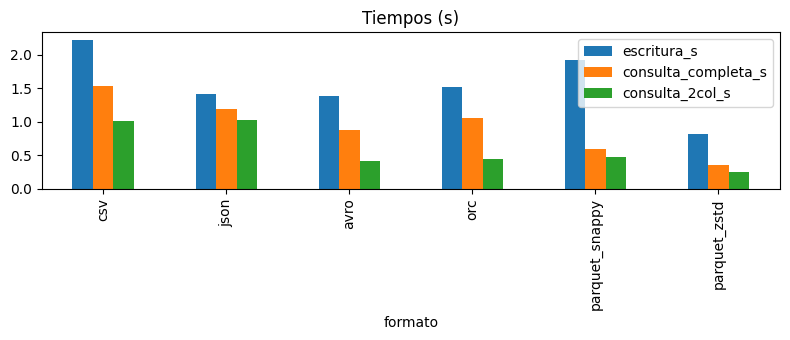

In [7]:
ax = comparativa[["MB"]].plot.bar(figsize=(8, 3.5), legend=False, title="Tamaño en HDFS (MB, sin réplicas)")
plt.tight_layout(); plt.savefig("/workspace/entregas/F1/formatos_tamano.png", dpi=120); plt.show()
ax = comparativa[["escritura_s", "consulta_completa_s", "consulta_2col_s"]].plot.bar(figsize=(8, 3.5), title="Tiempos (s)")
plt.tight_layout(); plt.savefig("/workspace/entregas/F1/formatos_tiempos.png", dpi=120); plt.show()

In [8]:
# ✏️ TAREA C1 · Repetimos las dos consultas 3 veces por formato sobre los ficheros ya escritos en /puerto/bench
# para medir la variabilidad (la 1.ª lectura suele ser la más lenta).
import time
reps = []
for nombre, fmt, opciones in formatos:
    lector = spark.read.format(fmt).options(**opciones)
    if fmt in ("csv", "json"):
        lector = lector.schema(ais.schema)
    df = lector.load(f"/puerto/bench/ais_{nombre}")
    for i in range(1, 4):
        t0 = time.time(); df.groupBy("mmsi").agg(F.avg("sog")).count(); t1 = time.time()
        df.select("lat", "lon").where("lat > 37.1").count(); t2 = time.time()
        reps.append({"formato": nombre, "rep": i, "completa_s": round(t1 - t0, 3), "dos_col_s": round(t2 - t1, 3)})
repeticiones = pd.DataFrame(reps)
repeticiones.to_csv("/workspace/entregas/F1/comparativa_repeticiones.csv", index=False)
print(repeticiones.pivot(index="formato", columns="rep", values=["completa_s", "dos_col_s"]))
repeticiones.groupby("formato")[["completa_s", "dos_col_s"]].agg(["min", "mean", "max"]).round(3)

               completa_s               dos_col_s              
rep                     1      2      3         1      2      3
formato                                                        
avro                0.393  0.438  0.397     0.297  0.323  0.307
csv                 0.684  0.598  0.662     0.546  0.467  0.482
json                0.919  0.708  0.672     0.579  0.612  0.537
orc                 0.271  0.280  0.241     0.255  0.236  0.181
parquet_snappy      0.220  0.232  0.266     0.220  0.179  0.185
parquet_zstd        0.208  0.259  0.246     0.202  0.223  0.181


completa_s               dos_col_s              
                      min   mean    max       min   mean    max
formato                                                        
avro                0.393  0.409  0.438     0.297  0.309  0.323
csv                 0.598  0.648  0.684     0.467  0.498  0.546
json                0.672  0.766  0.919     0.537  0.576  0.612
orc                 0.241  0.264  0.280     0.181  0.224  0.255
parquet_snappy      0.220  0.239  0.266     0.179  0.195  0.220
parquet_zstd        0.208  0.238  0.259     0.181  0.202  0.223

**✏️ TAREA C1.** Repetid la medición una segunda vez: ¿cambian los tiempos? ¿Por qué la primera ejecución suele ser
más lenta? **✏️ TAREA C2.** Explicad en la memoria, con vuestros números: formato por filas vs. columnar, compresión,
esquema embebido, lectura de solo 2 columnas (*column pruning*) y si el formato es «divisible» (*splittable*).
Elegid y justificad el formato para las zonas bronze, silver y gold.

## D · Zona *bronze*: Parquet particionado por fecha
Añadimos **metadatos de linaje** (fichero de origen y momento de ingesta) y particionamos por fecha:
cada día queda en su carpeta `fecha=AAAA-MM-DD`, y las consultas que filtran por fecha solo leen esas carpetas
(*partition pruning*).

In [9]:
ais_bronze = (ais
    .withColumn("ts", F.to_timestamp("ts"))
    .withColumn("fecha", F.to_date("ts"))
    .withColumn("_fichero_origen", F.input_file_name())
    .withColumn("_ingestado", F.current_timestamp()))
(ais_bronze.repartition("fecha")
    .write.mode("overwrite").partitionBy("fecha").parquet("/puerto/bronze/ais"))
h.ls("/puerto/bronze/ais")

tipo      réplicas  bloque       tamaño  nombre
FILE             3  128 MB        0.0 B  _SUCCESS
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-01
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-02
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-03
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-04
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-05
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-06
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-07
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-08
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-09
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-10
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-11
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-12
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-13
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-14
DIRECTORY        0    0 MB        0.0 B  fecha=2025-06-15
DIRECTORY        0    0 MB      

In [10]:
b = spark.read.parquet("/puerto/bronze/ais")
consulta = b.filter(F.col("fecha") == "2025-06-15").groupBy("estado_nav").count()
consulta.explain()      # buscad «PartitionFilters» en el plan físico
consulta.show()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[estado_nav#3415], functions=[count(1)])
   +- Exchange hashpartitioning(estado_nav#3415, 8), ENSURE_REQUIREMENTS, [plan_id=3819]
      +- HashAggregate(keys=[estado_nav#3415], functions=[partial_count(1)])
         +- Project [estado_nav#3415]
            +- FileScan parquet [estado_nav#3415,fecha#3419] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[hdfs://namenode:8020/puerto/bronze/ais], PartitionFilters: [isnotnull(fecha#3419), (fecha#3419 = 2025-06-15)], PushedFilters: [], ReadSchema: struct<estado_nav:int>


+----------+-----+
|estado_nav|count|
+----------+-----+
|         5| 5403|
|         1| 1157|
|         0| 6746|
+----------+-----+



Hacemos lo mismo con las **escalas** (particionadas por año). Ojo: algunas fechas vienen como `dd/MM/yyyy HH:mm`,
por eso probamos los dos formatos con `coalesce`.

In [11]:
def a_timestamp(c):
    return F.coalesce(F.to_timestamp(c, "yyyy-MM-dd HH:mm:ss"), F.to_timestamp(c, "dd/MM/yyyy HH:mm"))

escalas_bronze = (escalas_raw
    .withColumn("eta", a_timestamp("eta")).withColumn("ata", a_timestamp("ata")).withColumn("atd", a_timestamp("atd"))
    .withColumn("anio", F.year("eta"))
    .withColumn("_fichero_origen", F.input_file_name())
    .withColumn("_ingestado", F.current_timestamp()))
escalas_bronze.write.mode("overwrite").partitionBy("anio").parquet("/puerto/bronze/escalas")
h.ls("/puerto/bronze/escalas")

tipo      réplicas  bloque       tamaño  nombre
FILE             3  128 MB        0.0 B  _SUCCESS
DIRECTORY        0    0 MB        0.0 B  anio=2024
DIRECTORY        0    0 MB        0.0 B  anio=2025


**✏️ TAREA D1.** Cread la zona bronze de **sensores** (`/puerto/bronze/sensores`, particionado por fecha; el campo `ts`
trae zona horaria `+02:00`), de **contenedores** (`/puerto/bronze/contenedores`) y de los tres **maestros**
(`/puerto/bronze/maestros/<nombre>`). Declarad siempre el esquema.
**✏️ TAREA D2.** Explicad el problema de los «ficheros pequeños» (*small files*) en HDFS y por qué hacemos `repartition("fecha")`
antes de escribir.

In [12]:
# ✏️ TAREA D1 · bronze de sensores, contenedores y maestros (esquemas según docs/DICCIONARIO_DATOS.md)

# 0. Primeras líneas reales de cada fuente (comprobación del orden de columnas)
for ruta in ["/puerto/raw/sensores/", "/puerto/raw/contenedores/", "/puerto/raw/maestros/muelles.csv",
             "/puerto/raw/maestros/navieras.csv", "/puerto/raw/maestros/buques.csv"]:
    print(ruta); spark.read.text(ruta).show(2, truncate=False)

def nulos_tras_convertir(df_raw, df_bronze, columnas):
    """Cuenta valores que venían rellenos en raw y han quedado en null al convertir el tipo."""
    return {c: df_bronze.filter(F.col(c).isNull()).count() - df_raw.filter(F.col(c).isNull()).count()
            for c in columnas}

# ==========================================
# 1. SENSORES · formato largo, particionado por fecha
# ==========================================
esquema_sensores = T.StructType([
    T.StructField("ts", T.StringType()),          # hora local con desfase +02:00
    T.StructField("id_sensor", T.StringType()),
    T.StructField("variable", T.StringType()),
    T.StructField("valor", T.StringType()),       # lo leemos como texto y lo convertimos (así vemos los fallos)
    T.StructField("unidad", T.StringType()),
])
sensores_raw = spark.read.schema(esquema_sensores).option("header", True).csv("/puerto/raw/sensores/")

sensores_bronze = (sensores_raw
    .withColumn("fecha", F.to_date(F.substring("ts", 1, 10)))   # día LOCAL, igual que el nombre del fichero
    .withColumn("ts", F.to_timestamp("ts"))                     # el +02:00 se respeta: instante correcto
    .withColumn("valor", F.col("valor").cast("double"))
    .withColumn("_fichero_origen", F.input_file_name())
    .withColumn("_ingestado", F.current_timestamp()))

(sensores_bronze.repartition("fecha")
    .write.mode("overwrite").partitionBy("fecha").parquet("/puerto/bronze/sensores"))
sensores_bronze.printSchema()
print("Bronze sensores · filas:", sensores_bronze.count(),
      "· fallos de conversión:", nulos_tras_convertir(sensores_raw, sensores_bronze, ["ts", "valor"]))

# ==========================================
# 2. CONTENEDORES · movimientos de 2025
# ==========================================
esquema_contenedores = T.StructType([T.StructField(c, T.StringType()) for c in [
    "id_movimiento", "ts", "contenedor", "codigo_iso", "tipo", "lleno", "peso_bruto_kg", "id_escala",
    "id_cliente", "movimiento", "bloque_patio", "clase_imo", "temp_consigna_c"]])
contenedores_raw = spark.read.schema(esquema_contenedores).option("header", True).csv("/puerto/raw/contenedores/")

contenedores_bronze = (contenedores_raw
    .withColumn("ts", F.coalesce(F.to_timestamp("ts"), F.to_timestamp("ts", "dd/MM/yyyy HH:mm")))
    .withColumn("peso_bruto_kg", F.col("peso_bruto_kg").cast("double"))
    .withColumn("temp_consigna_c", F.col("temp_consigna_c").cast("double"))
    .withColumn("_fichero_origen", F.input_file_name())
    .withColumn("_ingestado", F.current_timestamp()))

contenedores_bronze.write.mode("overwrite").parquet("/puerto/bronze/contenedores")
contenedores_bronze.printSchema()
print("Bronze contenedores · filas:", contenedores_bronze.count(), "· fallos de conversión:",
      nulos_tras_convertir(contenedores_raw, contenedores_bronze, ["ts", "peso_bruto_kg", "temp_consigna_c"]))

# ==========================================
# 3. MAESTROS · esquema declarado (sin inferSchema), sin particionar, 1 fichero
# ==========================================
S, D, I = T.StringType(), T.DoubleType(), T.IntegerType()
esquemas_maestros = {
    "muelles":  [("id_muelle", S), ("nombre", S), ("tipo", S), ("calado_max_m", D), ("longitud_m", D),
                 ("lat", D), ("lon", D), ("gruas", S)],
    "navieras": [("id_naviera", S), ("nombre", S), ("pais", S), ("flota", I)],
    "buques":   [("imo", S), ("mmsi", S), ("nombre", S), ("tipo", S), ("descripcion_tipo", S), ("gt", D),
                 ("eslora_m", D), ("manga_m", D), ("calado_m", D), ("bandera", S), ("id_naviera", S)],
}
for maestro, campos in esquemas_maestros.items():
    esquema = T.StructType([T.StructField(c, t) for c, t in campos])
    df_maestro = (spark.read.schema(esquema).option("header", True)
                  .csv(f"/puerto/raw/maestros/{maestro}.csv")
                  .withColumn("_fichero_origen", F.input_file_name())
                  .withColumn("_ingestado", F.current_timestamp()))
    df_maestro.coalesce(1).write.mode("overwrite").parquet(f"/puerto/bronze/maestros/{maestro}")
    print(f"Bronze {maestro} · filas:", df_maestro.count())

# 4. Comprobación: la zona bronze completa
h.ls("/puerto/bronze")
h.ls("/puerto/bronze/maestros")

/puerto/raw/sensores/
+------------------------------------------------------+
|value                                                 |
+------------------------------------------------------+
|ts,id_sensor,variable,valor,unidad                    |
|2025-07-27T00:00:00+02:00,METEO-01,viento_vel,7.96,m/s|
+------------------------------------------------------+
only showing top 2 rows

/puerto/raw/contenedores/
+--------------------------------------------------------------------------------------------------------------------------------------+
|value                                                                                                                                 |
+--------------------------------------------------------------------------------------------------------------------------------------+
|id_movimiento,ts,contenedor,codigo_iso,tipo,lleno,peso_bruto_kg,id_escala,id_cliente,movimiento,bloque_patio,clase_imo,temp_consigna_c|
|MOV00000001,2025-01-02 21:09:18,TNTU

root
 |-- ts: timestamp (nullable = true)
 |-- id_sensor: string (nullable = true)
 |-- variable: string (nullable = true)
 |-- valor: double (nullable = true)
 |-- unidad: string (nullable = true)
 |-- fecha: date (nullable = true)
 |-- _fichero_origen: string (nullable = false)
 |-- _ingestado: timestamp (nullable = false)



Bronze sensores · filas: 1348728 · fallos de conversión: {'ts': 0, 'valor': 0}


root
 |-- id_movimiento: string (nullable = true)
 |-- ts: timestamp (nullable = true)
 |-- contenedor: string (nullable = true)
 |-- codigo_iso: string (nullable = true)
 |-- tipo: string (nullable = true)
 |-- lleno: string (nullable = true)
 |-- peso_bruto_kg: double (nullable = true)
 |-- id_escala: string (nullable = true)
 |-- id_cliente: string (nullable = true)
 |-- movimiento: string (nullable = true)
 |-- bloque_patio: string (nullable = true)
 |-- clase_imo: string (nullable = true)
 |-- temp_consigna_c: double (nullable = true)
 |-- _fichero_origen: string (nullable = false)
 |-- _ingestado: timestamp (nullable = false)

Bronze contenedores · filas: 400182 · fallos de conversión: {'ts': 0, 'peso_bruto_kg': 0, 'temp_consigna_c': 0}
Bronze muelles · filas: 12
Bronze navieras · filas: 40
Bronze buques · filas: 320
tipo      réplicas  bloque       tamaño  nombre
DIRECTORY        0    0 MB        0.0 B  ais
DIRECTORY        0    0 MB        0.0 B  contenedores
DIRECTORY        0

## E · Procesamiento con Spark SQL
Registramos las tablas bronze como vistas y respondemos preguntas del cliente. Filtramos de momento los valores
absurdos de toneladas; la limpieza completa llega en la fase 3.

In [13]:
spark.read.parquet("/puerto/bronze/escalas").createOrReplaceTempView("escalas")
spark.read.option("header", True).csv("/puerto/raw/maestros/navieras.csv").createOrReplaceTempView("navieras")

trafico = spark.sql('''
    SELECT date_format(eta, 'yyyy-MM') AS mes, tipo_trafico,
           COUNT(*) AS escalas, ROUND(SUM(toneladas) / 1000, 1) AS miles_t
    FROM escalas
    WHERE toneladas BETWEEN 0 AND 500000
    GROUP BY 1, 2 ORDER BY 1, 2''')
trafico.write.mode("overwrite").parquet("/puerto/gold/f1_trafico_mensual")
trafico.show(10)

+-------+-----------------+-------+-------+
|    mes|     tipo_trafico|escalas|miles_t|
+-------+-----------------+-------+-------+
|2024-01|    carga_general|     20|  186.8|
|2024-01|     contenedores|     34|  396.0|
|2024-01|fruta_refrigerada|      7|   68.4|
|2024-01|   granel_liquido|     76| 3443.3|
|2024-01|    granel_solido|     56| 1497.9|
|2024-01|        pasajeros|     10|    0.0|
|2024-01|            pesca|     21|    0.9|
|2024-01|            ro_ro|     23|  406.1|
|2024-02|    carga_general|     23|  184.8|
|2024-02|     contenedores|     32|  335.5|
+-------+-----------------+-------+-------+
only showing top 10 rows



In [14]:
espera = spark.sql('''
    SELECT tipo_trafico, year(eta) AS anio, quarter(eta) AS trimestre,
           ROUND(AVG((unix_timestamp(ata) - unix_timestamp(eta)) / 3600), 1) AS espera_media_h,
           COUNT(*) AS escalas
    FROM escalas
    WHERE ata IS NOT NULL AND eta IS NOT NULL
    GROUP BY 1, 2, 3 ORDER BY 1, 2, 3''')
espera.write.mode("overwrite").parquet("/puerto/gold/f1_espera_trimestral")
espera.filter("tipo_trafico = 'contenedores'").show()

+------------+----+---------+--------------+-------+
|tipo_trafico|anio|trimestre|espera_media_h|escalas|
+------------+----+---------+--------------+-------+
|contenedores|2024|        1|           4.6|    112|
|contenedores|2024|        2|           5.1|    115|
|contenedores|2024|        3|           4.5|     87|
|contenedores|2024|        4|           5.4|    112|
|contenedores|2025|        1|           5.1|    110|
|contenedores|2025|        2|           5.5|    104|
|contenedores|2025|        3|          15.6|    111|
|contenedores|2025|        4|           8.1|    109|
+------------+----+---------+--------------+-------+



**✏️ TAREA E1.** Escribid y guardad en `/puerto/gold/` al menos **tres** consultas más que respondan a:
1. Las 10 navieras con más toneladas movidas en 2025 (con su nombre, uniendo con `navieras`).
2. La ocupación de cada muelle: horas atracadas (`atd - ata`) por mes.
3. Una pregunta que propongáis vosotros usando AIS o sensores (p. ej. velocidad media de entrada, horas con viento > 14 m/s).

In [15]:
# ✏️ TAREA E1

# 1. Las 10 navieras con más toneladas movidas en 2025
consulta1 = spark.sql('''
    SELECT n.nombre AS naviera, SUM(e.toneladas) AS total_toneladas
    FROM escalas e
    JOIN navieras n ON e.id_naviera = n.id_naviera
    WHERE year(e.eta) = 2025 AND e.toneladas BETWEEN 0 AND 500000
    GROUP BY n.nombre
    ORDER BY total_toneladas DESC
    LIMIT 10
''')
consulta1.write.mode("overwrite").parquet("/puerto/gold/f1_top_navieras")
print("Top 10 Navieras guardado en Gold.")
consulta1.show(10, truncate=False)


# 2. La ocupación de cada muelle por mes
consulta2 = spark.sql('''
    SELECT id_muelle, date_format(ata, 'yyyy-MM') AS mes,
           ROUND(SUM((unix_timestamp(atd) - unix_timestamp(ata)) / 3600), 1) AS horas_ocupado
    FROM escalas
    WHERE ata IS NOT NULL AND atd IS NOT NULL
    GROUP BY id_muelle, mes
    ORDER BY mes DESC, horas_ocupado DESC
''')
consulta2.write.mode("overwrite").parquet("/puerto/gold/f1_ocupacion_muelles")
print("Ocupación de muelles guardada en Gold.")
consulta2.show(10)


# 3. Velocidad media por estado de navegación (AIS)
# ⚠️ AÑADIMOS ESTA LÍNEA PARA REGISTRAR LA TABLA AIS:
spark.read.parquet("/puerto/bronze/ais").createOrReplaceTempView("ais")

consulta3 = spark.sql('''
    SELECT estado_nav, ROUND(AVG(sog), 2) AS velocidad_media_nudos, COUNT(*) AS registros
    FROM ais
    WHERE sog > 0
    GROUP BY estado_nav
    ORDER BY velocidad_media_nudos DESC
''')
consulta3.write.mode("overwrite").parquet("/puerto/gold/f1_velocidad_por_estado")
print("Velocidad media por estado guardada en Gold.")
consulta3.show()

Top 10 Navieras guardado en Gold.
+---------------------+------------------+
|naviera              |total_toneladas   |
+---------------------+------------------+
|Azores Naviera       |3597799.600000002 |
|Atlántica Naviera    |3560319.800000001 |
|Tinto Maritime       |2898360.6999999993|
|Iberia Maritime      |2839038.699999999 |
|Mare Nostrum Maritime|2783717.5000000014|
|Canarias Maritime    |2769535.8000000007|
|Levante Shipping     |2738114.799999999 |
|Blue Wave Maritime   |2696156.0         |
|Cabo Verde Maritime  |2692974.4         |
|Blue Wave Carriers   |2533464.7         |
+---------------------+------------------+

Ocupación de muelles guardada en Gold.
+---------+-------+-------------+
|id_muelle|    mes|horas_ocupado|
+---------+-------+-------------+
|      M12|2026-01|         41.9|
|      M06|2026-01|         28.4|
|      M04|2026-01|         27.2|
|      M01|2026-01|         16.8|
|      M02|2025-12|       1850.5|
|      M03|2025-12|       1257.0|
|      M04|2025-12

Velocidad media por estado guardada en Gold.
+----------+---------------------+---------+
|estado_nav|velocidad_media_nudos|registros|
+----------+---------------------+---------+
|         0|                10.91|   592536|
|         5|                 0.15|   226272|
|         1|                 0.15|    40557|
+----------+---------------------+---------+



In [16]:
# ✏️ TAREA E1 (más consultas propias con AIS y sensores)

# 4. Buques distintos por día en la 2.ª quincena de junio + media móvil de 7 días (función de ventana).
#    Filtra por la columna de partición «fecha»: el plan debe mostrar PartitionFilters.
consulta4 = spark.sql('''
    SELECT fecha, buques,
           ROUND(AVG(buques) OVER (ORDER BY fecha ROWS BETWEEN 6 PRECEDING AND CURRENT ROW), 1) AS media_7d
    FROM (SELECT fecha, COUNT(DISTINCT mmsi) AS buques
          FROM ais
          WHERE fecha BETWEEN '2025-06-15' AND '2025-06-30'
          GROUP BY fecha)
    ORDER BY fecha''')
consulta4.explain()
consulta4.write.mode("overwrite").parquet("/puerto/gold/f1_buques_dia_ais")
consulta4.show(16)

# 5. Horas al día con viento > 14 m/s (umbral a partir del cual paran las grúas), con la racha máxima.
#    METEO-01 mide cada minuto: minutos por encima del umbral / 60 = horas.
spark.read.parquet("/puerto/bronze/sensores").createOrReplaceTempView("sensores")
consulta5 = spark.sql('''
    SELECT fecha,
           ROUND(SUM(CASE WHEN valor > 14 THEN 1 ELSE 0 END) / 60, 1) AS horas_viento_fuerte,
           ROUND(MAX(valor), 1) AS viento_max_ms
    FROM sensores
    WHERE id_sensor = 'METEO-01' AND variable = 'viento_vel' AND valor BETWEEN 0 AND 60
    GROUP BY fecha
    HAVING horas_viento_fuerte > 0
    ORDER BY horas_viento_fuerte DESC''')
consulta5.write.mode("overwrite").parquet("/puerto/gold/f1_viento_gruas")
print("Días con viento por encima de 14 m/s:", consulta5.count())
consulta5.show(10)

h.ls("/puerto/gold")

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [fecha#4495, buques#4548L, round(_we0#4552, 1) AS media_7d#4549]
   +- Window [avg(buques#4548L) windowspecdefinition(fecha#4495 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -6, currentrow$())) AS _we0#4552], [fecha#4495 ASC NULLS FIRST]
      +- Sort [fecha#4495 ASC NULLS FIRST], false, 0
         +- Exchange SinglePartition, ENSURE_REQUIREMENTS, [plan_id=5965]
            +- HashAggregate(keys=[fecha#4495], functions=[count(distinct mmsi#4485)])
               +- Exchange hashpartitioning(fecha#4495, 8), ENSURE_REQUIREMENTS, [plan_id=5962]
                  +- HashAggregate(keys=[fecha#4495], functions=[partial_count(distinct mmsi#4485)])
                     +- HashAggregate(keys=[fecha#4495, mmsi#4485], functions=[])
                        +- Exchange hashpartitioning(fecha#4495, mmsi#4485, 8), ENSURE_REQUIREMENTS, [plan_id=5958]
                           +- HashAggregate(keys=[fecha#4495, mmsi#4485], functions

26/11/18 19:03:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 19:03:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 19:03:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 19:03:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 19:03:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 19:03:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 1

+----------+------+--------+
|     fecha|buques|media_7d|
+----------+------+--------+
|2025-06-15|    31|    31.0|
|2025-06-16|    32|    31.5|
|2025-06-17|    36|    33.0|
|2025-06-18|    30|    32.3|
|2025-06-19|    38|    33.4|
|2025-06-20|    37|    34.0|
|2025-06-21|    36|    34.3|
|2025-06-22|    26|    33.6|
|2025-06-23|    22|    32.1|
|2025-06-24|    29|    31.1|
|2025-06-25|    28|    30.9|
|2025-06-26|    31|    29.9|
|2025-06-27|    40|    30.3|
|2025-06-28|    36|    30.3|
|2025-06-29|    37|    31.9|
|2025-06-30|    40|    34.4|
+----------+------+--------+



Días con viento por encima de 14 m/s: 4
+----------+-------------------+-------------+
|     fecha|horas_viento_fuerte|viento_max_ms|
+----------+-------------------+-------------+
|2025-07-10|                7.0|         17.3|
|2025-06-23|                5.9|         16.9|
|2025-06-06|                1.5|         15.3|
|2025-07-27|                0.8|         15.8|
+----------+-------------------+-------------+

tipo      réplicas  bloque       tamaño  nombre
DIRECTORY        0    0 MB        0.0 B  f1_buques_dia_ais
DIRECTORY        0    0 MB        0.0 B  f1_espera_trimestral
DIRECTORY        0    0 MB        0.0 B  f1_ocupacion_muelles
DIRECTORY        0    0 MB        0.0 B  f1_top_navieras
DIRECTORY        0    0 MB        0.0 B  f1_trafico_mensual
DIRECTORY        0    0 MB        0.0 B  f1_velocidad_por_estado
DIRECTORY        0    0 MB        0.0 B  f1_viento_gruas


## F · Presentación al cliente
El cliente no lee tablas de Spark. Convertimos los resultados *gold* (pequeños) a pandas y hacemos gráficos claros.

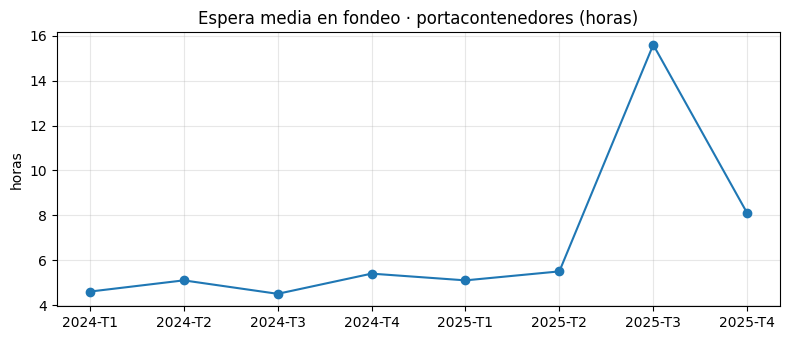

In [17]:
pdf = espera.filter("tipo_trafico = 'contenedores'").toPandas()
pdf["periodo"] = pdf["anio"].astype(str) + "-T" + pdf["trimestre"].astype(str)
ax = pdf.plot(x="periodo", y="espera_media_h", marker="o", legend=False, figsize=(8, 3.5),
              title="Espera media en fondeo · portacontenedores (horas)")
ax.set_xlabel(""); ax.set_ylabel("horas"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("/workspace/entregas/F1/espera_contenedores.png", dpi=120); plt.show()

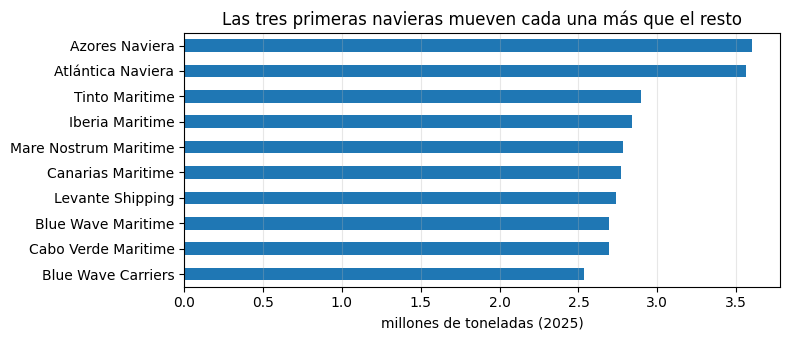

              naviera  millones_t
   Blue Wave Carriers        2.53
  Cabo Verde Maritime        2.69
   Blue Wave Maritime        2.70
     Levante Shipping        2.74
    Canarias Maritime        2.77
Mare Nostrum Maritime        2.78
      Iberia Maritime        2.84
       Tinto Maritime        2.90
    Atlántica Naviera        3.56
       Azores Naviera        3.60
+-----------------+----+---------+--------------+-------+
|     tipo_trafico|anio|trimestre|espera_media_h|escalas|
+-----------------+----+---------+--------------+-------+
|    carga_general|2024|        1|           6.0|     57|
|     contenedores|2024|        1|           4.6|    112|
|fruta_refrigerada|2024|        1|           4.1|    139|
|   granel_liquido|2024|        1|           7.6|    223|
|    granel_solido|2024|        1|           8.8|    183|
|        pasajeros|2024|        1|           0.3|     34|
|            pesca|2024|        1|           0.2|     73|
|            ro_ro|2024|        1|           1

In [18]:
# Gráfico 2 del informe: navieras con más toneladas en 2025 (el título dice la conclusión)
nav = consulta1.toPandas().sort_values("total_toneladas")
nav["millones_t"] = nav["total_toneladas"] / 1e6
ax = nav.plot.barh(x="naviera", y="millones_t", legend=False, figsize=(8, 3.5),
                   title="Las tres primeras navieras mueven cada una más que el resto")
ax.set_xlabel("millones de toneladas (2025)"); ax.set_ylabel(""); ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.savefig("/workspace/entregas/F1/top_navieras.png", dpi=120); plt.show()
print(nav[["naviera", "millones_t"]].round(2).to_string(index=False))

# Datos para el informe: espera de portacontenedores y del resto de tráficos por trimestre
espera.orderBy("anio", "trimestre", "tipo_trafico").show(100)

**✏️ TAREA F1.** Preparad un **informe ejecutivo de una página** en `entregas/F1/MEMORIA_F1.md` (apartado CE1.e) para la
dirección del puerto: 3 gráficos como máximo, 3 conclusiones en lenguaje no técnico y una recomendación.
¿Qué ha pasado con la espera de los portacontenedores en 2025?

In [19]:
spark.stop()